# NLP — 14. Attention

We're now entering one of the **most important concepts in NLP and Generative AI.**

We've studied RNN, LSTM, GRU, Seq2Seq, and Encoder–Decoder. Now we'll understand the problem that led to Attention and how Attention solves it.

## 1. Why do we need Attention?

Imagine translating this sentence from English to French:

> "The animal didn't cross the street because it was too tired."

When translating the word **"it"**, the model needs to understand which earlier word it refers to: "animal".
Now consider a longer sentence. The information needed to generate a particular output word might be located far back in the input.
A basic encoder–decoder model may compress the entire input into a single fixed-size representation. This can make long sequences difficult to handle.

The decoder has limited access to the details of the original input.

**Attention was introduced to help the decoder access the most relevant parts of the input when generating each output token.**

## 2. What is Attention?

**Attention is a mechanism that allows a model to assign different levels of importance to different parts of the input.**

Think about reading a question and searching a paragraph for the information needed to answer it.

You don't treat every word in the paragraph as equally important. You focus on the relevant words.

Attention works in a similar way.

Consider translating:

When generating `chats`, the model should focus strongly on `cats`.

When generating `J'aime`, it should focus more on `I love.`

Conceptually:

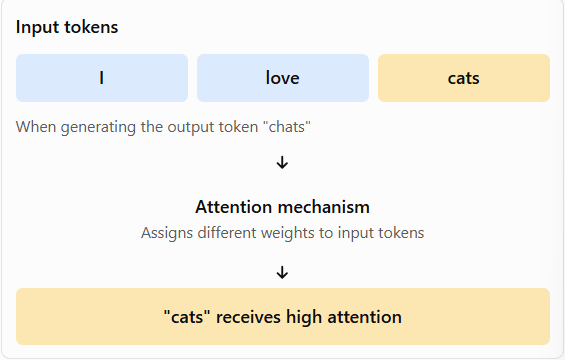

## 3. How does Attention work?

At a high level, the process has three steps.

**1. Calculate relevance:** Determine how relevant each input token is to the current task or output token.

**2. Calculate attention weights:** Convert the relevance scores into weights, commonly using the softmax function.

**3. Combine information:** Use the weights to create a representation that emphasizes the more relevant information.

For example, suppose the model needs to generate the word chats.

Imagine it calculates these attention weights:

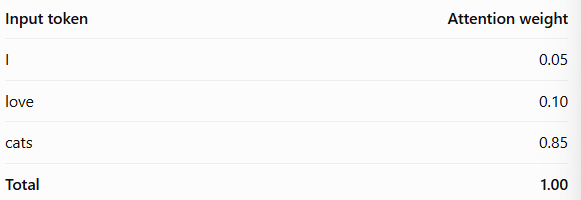

These are illustrative numbers. They show how the model could assign greater importance to `cats` for this output.


The weights are combined with representations of the input tokens to produce a **context vector.**

A higher attention weight means a token contributes more strongly to that particular attention calculation. It doesn't automatically mean the token is universally more important.

## 4. Attention versus the basic Encoder-Decoder

This is the central difference.

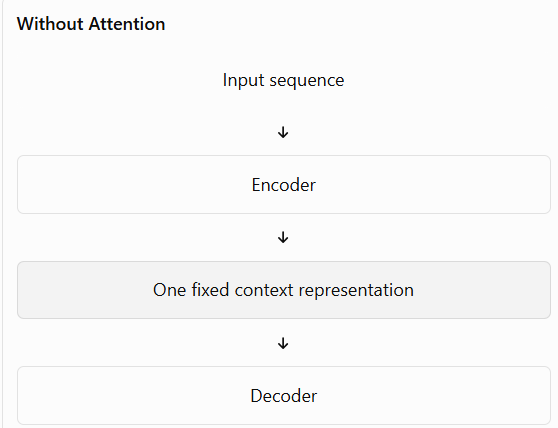

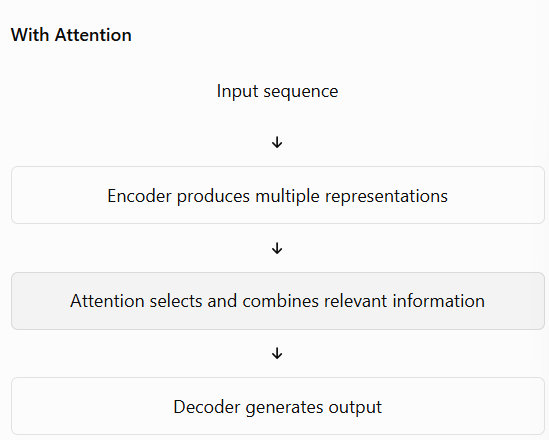

In classic attention-based Seq2Seq models, the decoder can use a different weighted combination of encoder states at each output step.

This reduces the information bottleneck of relying only on one fixed representation.

## 5. What are Query, Key, and Value?

You'll see these three terms repeatedly when learning Transformers.

They are the building blocks of the modern **scaled dot-product attention** mechanism.

A useful analogy is a search system:

- **Query (Q):** What information am I looking for?
- **Key (K):** What information does each available item correspond to?
- **Value (V):** What information does each item contain that I can retrieve?

Attention compares the query with the keys to calculate relevance scores, then uses those scores to combine the values.

For now, remember:

**Query searches, Key matches, Value provides the information.**

```
Q → [what we’re looking for]
K → [what we have]
V → [information to return]
```

We'll derive the actual equations in the next lessons.

## 6. Different types of Attention

There are several related concepts. They shouldn't be treated as identical.

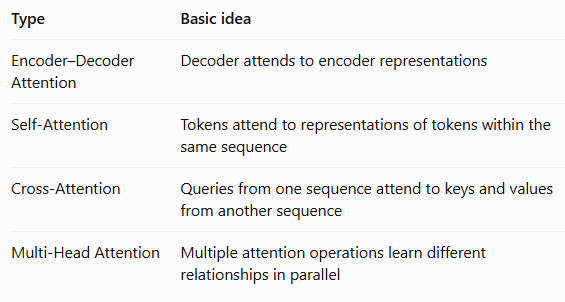

These concepts will become clearer when we study Query, Key, and Value.

One important distinction: **self-attention is not the same as cross-attention.** In self-attention, queries, keys, and values come from the same sequence representation; in cross-attention, queries come from one sequence and keys/values from another.

## 7. Why is Attention important for GenAI?

There are five major reasons 

### ① Understands relationships between words

Consider:

"The dog chased the cat because it was running."

To interpret **"it"**, the model needs to consider the surrounding words.

Attention helps the model learn relationships between tokens, including relationships between words that are far apart.

### ② Handles long sequences better

Without attention, a basic sequence-to-sequence model may struggle to preserve all the information in a long input.

Attention provides direct access to relevant encoder states, helping reduce this bottleneck.

### ③ Enables Transformers

This is the biggest connection to modern GenAI.

The Transformer architecture, introduced in the 2017 paper *Attention Is All You Need*, uses attention as a core mechanism rather than relying on recurrent processing.

### ④ Helps LLMs generate text

When you ask ChatGPT a question, the model processes tokens and uses attention to learn which other tokens are relevant to its next-token prediction.

For example:

**Prompt:** "Python is a programming language. It is widely used for ______."

The model can use the relationship between "Python," "programming language," and the surrounding context to predict a suitable continuation.

Attention helps the model use contextual information; it does not guarantee that the answer will be correct.

### ⑤ Supports many GenAI applications

Attention is important in systems that perform tasks such as:

- Text generation and summarization
- Machine translation
- Question answering
- Code generation
- Image generation using Transformer-based architectures
- Multimodal tasks involving text, images, and other data

In [ ]:
#Attention helps models process relationships between tokens and determine which information to use when building representations.
#It is a foundational component of the Transformer architecture, which underpins many modern language models.

## 8. What you should remember

- **Attention** assigns different weights to information based on relevance.
- It helps address the information bottleneck in early Seq2Seq architectures.
- Attention weights are used to combine input representations into a context-aware representation.
- **Query, Key, and Value** are central to scaled dot-product attention.
- **Self-attention** is a key building block of Transformers.

# NLP — 15. The Attention Mechanism: Query, Key, Value and Attention Scores.

In the previous lesson, we learned that Attention allows a model to focus on relevant parts of a sequence.

Now let's understand **how Attention calculates relevance mathematically.**

We'll cover the intuition, a numerical example, the formula, and a small Python implementation.

## 1. Understanding Query, Key, and Value

Imagine this sentence:

> "The cat sat on the mat because it was tired."

Suppose the model is processing the word **"it"** and needs to determine which earlier words are relevant.

Attention uses three vectors:

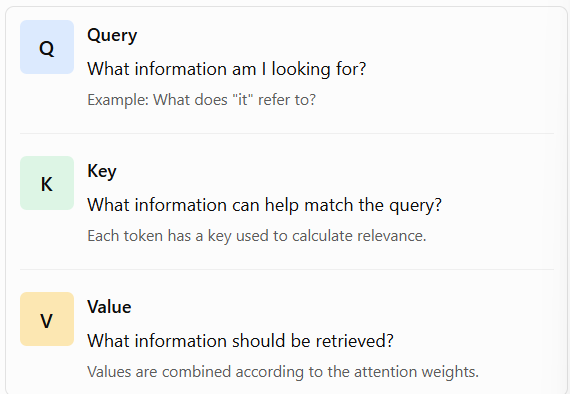

The key distinction is:

- **Query and Key** determine how strongly tokens relate.
- **Value** supplies the information that gets combined.

These are learned vector representations, not literal questions and labels.

## 2. How does Attention calculate relevance?

Suppose a query is compared with three keys.

For a simple example, imagine the similarity scores are:

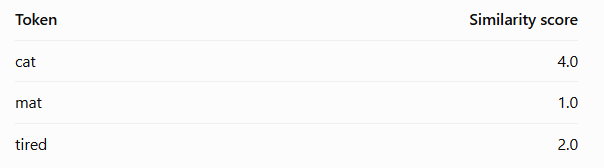

A higher score means the query matches that key more strongly in this example.

However, these scores aren't yet attention weights. We usually apply **softmax** to turn them into normalized weights.

Softmax converts scores into positive values that sum to 1.

For scores $s_1, s_2, \ldots, s_n$, the Softmax function calculates the attention weights:

$$
\alpha_i = \frac{e^{s_i}}{\displaystyle\sum_{j=1}^{n} e^{s_j}}
$$

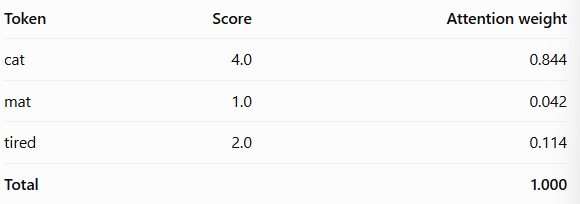

The model would give the `cat` value the largest contribution to the resulting representation.

*These numbers are illustrative, not actual scores from a trained model.*

## 3. The complete Attention formula

The standard **Scaled Dot-Product Attention** formula is:
$$
\boxed{\operatorname{Attention}(Q,K,V)=
\operatorname{softmax}\left(
\frac{QK^\top}{\sqrt{d_k}}
\right)V}
$$
Let's break it down.

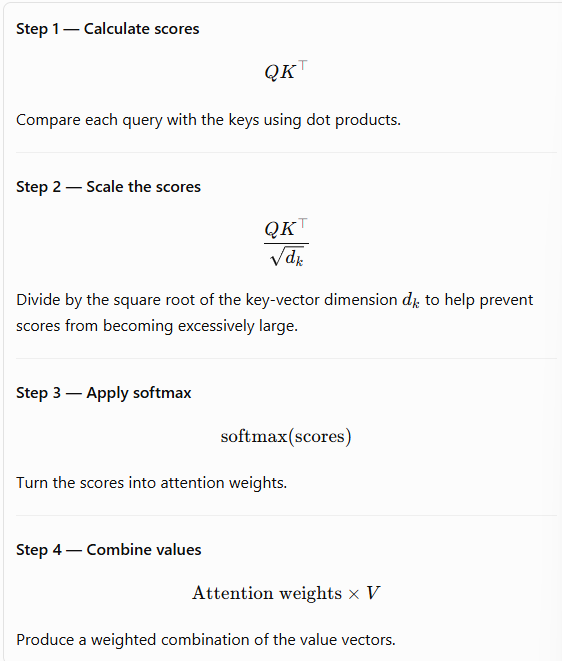

The final result is a new representation that incorporates information from the relevant tokens.

## 4. Why do we divide by $\sqrt{d_k}$?

### 1. What does $\sqrt{d_k}$ mean?

- Q = Query
- K = Key
- V = Value
- ${d_k}$ = Dimension of the key vectors
- $\sqrt{d_k}$ = Square root of the key dimension

### 2. Why do we divide by it?

**The main reason is to prevent attention scores from becoming too large.**

When the key and query vectors have many dimensions, their dot products can become large in magnitude.

Large scores can cause the Softmax function to produce extremely peaked probabilities, making its gradients very small and learning more difficult.

Dividing by $\sqrt{d_k}$ helps keep the scores at a suitable scale.

### 3. Simple numerical example

Suppose the dot product produces these attention scores:

$$
QK^T = [20,\ 10,\ 5]
$$

Assume the key dimension is $d_k = 16$.

Therefore,

$$
\sqrt{d_k} = \sqrt{16} = 4
$$

**Without Scaling:**

$$
\operatorname{Softmax}([20,\ 10,\ 5])
\approx [0.99995,\ 0.000045,\ 0.0000003]
$$

The first score dominates almost completely.

**With Scaling:**

Divide each score by $\sqrt{d_k} = 4$:

$$
\frac{[20,\ 10,\ 5]}{4}
=
[5,\ 2.5,\ 1.25]
$$

Now apply the Softmax function:

$$
\operatorname{Softmax}([5,\ 2.5,\ 1.25])
\approx [0.905,\ 0.074,\ 0.021]
$$

The scores are now less extreme, allowing other positions to receive more meaningful attention weights.

*Note: These values are illustrative.*

### 4. Remember This

| Without Scaling | With Scaling |
|---|---|
| Scores may become too large. | Scores are kept at a more suitable scale. |
| Softmax can produce extremely peaked probabilities. | Softmax is less likely to produce excessively peaked probabilities. |
| Gradients can become very small. | Helps maintain more useful gradients. |

**One-line takeaway:**

We divide the dot-product scores by $\sqrt{d_k}$ to prevent them from becoming too large, helping Softmax avoid extremely small gradients and supporting stable, effective training.

## 5. A small Python implementation

Let's implement the formula using NumPy. We'll use tiny, invented vectors to understand the mechanics.

In [2]:
# Import NumPy
import numpy as np

# Define Query(Q), Key(K), Value(V)
# For this example , we'll use three 2-dimensional vectors
# One query and three keys, each with 2 dimensions

Q = np.array([1, 0])

K = np.array([
    [1, 0],    # Key 1
    [0, 1],    # Key 2
    [1, 1]     # Key 3
])

# Each key has a corresponding value vector
V = np.array([
    [10, 0],
    [0, 10],
    [5, 5]
])

In [5]:
# Calculate the similarity scores

scores = Q @ K.T #The @ operator performs matrix multiplication. The query matches Keys 1 and 3 equally in this example.
print(scores)

[1 0 1]


In [7]:
# Scale the scores
d_k = K.shape[1]
scaled_scores = scores / np.sqrt(d_k)

print("Scaled_scores:",scaled_scores)

Scaled_scores: [0.70710678 0.         0.70710678]


In [8]:
# Apply softmax
# Softmax converts the scaled scores into attention weights that sum to 1.

def softmax(x):
    exp_x = np.exp(x - np.max(x))
    return exp_x / np.sum(exp_x)

attention_weights = softmax(scaled_scores)

print("Attention weights:", attention_weights)
print("Sum of weights:", attention_weights.sum())
#The first and third keys receive more attention than the second key.

Attention weights: [0.40111209 0.19777581 0.40111209]
Sum of weights: 1.0


In [10]:
# Calculate the attention output

attention_output = attention_weights @ V

print("Attention output:", attention_output)
#The output is a weighted combination of the three value vectors.

Attention output: [6.01668139 3.98331861]


In [11]:
# Why? The output combines the value vectors using the attention weights. Keys 1 and 3 receive more weight than Key 2.
#Important: This example demonstrates the mathematics. Real models learn their Q, K, and V projections from training data.

## 6. What happens inside a Transformer?

In a Transformer, input token representations are transformed using learned weight matrices:

$$
Q=XW_Q,\qquad K=XW_K,\qquad V=XW_V
$$

Here:
- $X$ = input token representations
- $W_Q$ = learned query projection
- $W_K$ = learned key projection
- $W_V$ = learned value projection

These projections allow the model to learn how to compare tokens and what information to pass between them.

The attention operation then combines the projected vectors according to the formula we just studied.

## Remember this formula

$$
\boxed{\operatorname{Attention}(Q,K,V)=
\operatorname{softmax}\left(
\frac{QK^\top}{\sqrt{d_k}}
\right)V}
$$

The next important concept is **Self-Attention.**

In self-attention, tokens within the same sequence can attend to one another. This allows the model to build context-aware representations without relying on a recurrent hidden state passing through the sequence one step at a time.

That is the next step toward understanding how Transformers work